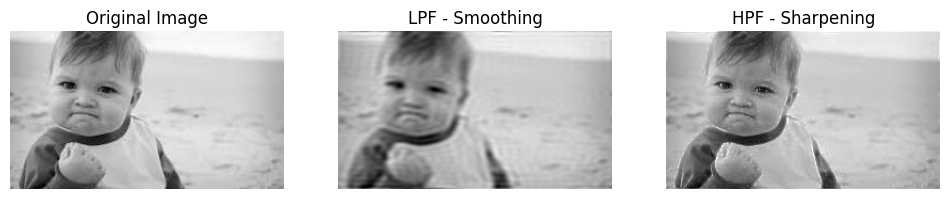

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the image in grayscale (change the path to your image)
img = cv2.imread('/Users/krishsondagar/Krish/sem_5/DSIP/labs/images/yes!.jpg', 0)

# 2. Fourier Transform (zero frequency shifted to the centre)
F = np.fft.fftshift(np.fft.fft2(img))
M, N = img.shape

# 3. Distance of every point from the centre of the spectrum
u, v = np.meshgrid(np.arange(N) - N//2, np.arange(M) - M//2)
D = np.sqrt(u**2 + v**2)

# 4. Ideal Low-Pass and High-Pass filters (cutoff radius D0 = 30)
D0 = 30
LPF = D < D0
HPF = D >= D0

# 5. Apply filters and go back to the spatial domain
smooth = np.abs(np.fft.ifft2(np.fft.ifftshift(F * LPF)))
high_pass = np.abs(np.fft.ifft2(np.fft.ifftshift(F * HPF)))
sharp = np.clip(img.astype(float) + high_pass, 0, 255)

# 6. Display the images
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(smooth, cmap='gray')
plt.title('LPF - Smoothing')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(sharp, cmap='gray')
plt.title('HPF - Sharpening')
plt.axis('off')
plt.show()